# 저장된 근거로 살펴보는 관계 기반 검색

이 노트북은 실제 실행에서 저장한 결과를 읽습니다. 검색 모델이나 LLM을 다시 호출하지 않습니다. 비교 대상은 용접 기록의 설정 번호와 코드북 설명을 연결하는 개발용 질문 24개입니다. 답변 생성은 아직 실행하지 않았습니다.


In [1]:
SNAPSHOT_SHA = '7c3b6dcb5b9ac955e30882dafa01211019943693ef668dd307d2c8b58695fa8e'
# 저장된 결과를 읽고 파일 해시를 확인합니다. 모델은 호출하지 않습니다.
import json, hashlib
from pathlib import Path
snapshot_path = Path("snapshot.json")
assert hashlib.sha256(snapshot_path.read_bytes()).hexdigest() == SNAPSHOT_SHA
s = json.loads(snapshot_path.read_text())
print("질문 수:", len(s["questions"]))
print(json.dumps(s["source_attribution"], ensure_ascii=False, indent=2))

질문 수: 24
{
  "authors": [
    "Tapia Suárez, Estefanía Alexandra",
    "Pérez Couñago, Inés",
    "Eike Precker, Christian",
    "Fernández Montenegro, Juan Manuel",
    "Ruiz, Cristina"
  ],
  "doi": "10.5281/zenodo.15083865",
  "extract_license": "CC-BY-4.0",
  "license": "CC-BY-4.0",
  "license_url": "https://creativecommons.org/licenses/by/4.0/",
  "metadata_sha256": "6af6d32eb8360e564580d828e9001f6775024fca045e261e0226a4b095e8d8b5",
  "metadata_url": "https://zenodo.org/api/records/15083865",
  "title": "Submerged Arc Welding Open Repository",
  "url": "https://zenodo.org/records/15083865",
  "version": "v2 (record landing page; absent in API metadata)"
}


## 원천 기록과 질문

PP4 작업표 2행의 설정 번호를 코드북에서 찾으면 명목 Idc를 확인할 수 있습니다. 작업표의 번호만으로는 값의 의미를 설명하기 어렵습니다. 여기서 명목 Idc는 코드북에 적힌 설정값이며 실제 측정값과는 다릅니다. 아래에는 저장된 질문과 해당 근거의 파일·시트·행 정보를 보여줍니다.


In [2]:
# 질문과 실제로 선택된 노드의 원천 위치를 보여줍니다.
qid = "dev-006"
print(next(q["question"] for q in s["questions"] if q["question_id"] == qid))
for c in s["examples"][qid]["C"]["selected_chunks"]:
    if c["chunk_type"] == "node":
        node = json.loads(c["text"])
        print(json.dumps({k:node.get(k) for k in ["id","archive_path","sheet","excel_row","code","values","dictionary_refs","sha256"]}, ensure_ascii=False, indent=2))

제공된 자료 안에서 PP4 작업표 2행의 설정 번호를 같은 파일의 코드북으로 해석하면 명목 Idc는 몇 A인가요? 실제 측정값과 구분하고 두 위치를 제시해주세요.
{
  "id": "PP4:2",
  "archive_path": "ZENODO_Penelope/PP4/2. ndt_data/defects_xlocation.xlsx",
  "sheet": "PP4",
  "excel_row": 2,
  "code": null,
  "values": {
    "bead": 1,
    "defect": 1,
    "sample_end": 140592,
    "sample_init": 139342,
    "welding_setting": 1,
    "x_end_mm": 225,
    "x_init_mm": 223
  },
  "dictionary_refs": {
    "defect": "PP4:defect_code:1",
    "welding_setting": "PP4:welding_settings_code:1"
  },
  "sha256": "f8c77fa0d0d8e702f23b2124db9b54bc7867b4609acd22c544f0cf6d09c9e39f"
}
{
  "id": "PP4:welding_settings_code:1",
  "archive_path": "ZENODO_Penelope/PP4/2. ndt_data/defects_xlocation.xlsx",
  "sheet": "welding_settings_code",
  "excel_row": 3,
  "code": 1,
  "values": [
    1,
    27,
    450,
    null,
    null,
    1.6,
    null,
    48
  ],
  "dictionary_refs": null,
  "sha256": "f8c77fa0d0d8e702f23b2124db9b54bc7867b4609acd22c544f0cf6d09c9e39f"
}


## 비교 조건과 실행 범위

A는 벡터 검색, B는 키워드·벡터 검색과 재순위화, C는 B의 선택 근거에서 관계를 따라 확장한 결과입니다. E는 C와 같은 규칙을 SQL/Python으로 구현했습니다. D는 C의 근거를 그대로 두고 검사 보고서만 덧붙입니다. 이 실험에서는 RDF·OWL 추론이나 SHACL 엔진을 실행하지 않았습니다.


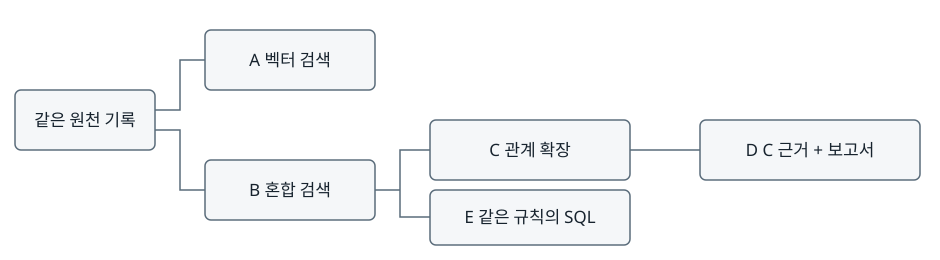

C/E: 같은 근거·규칙, 다른 순회 구현 / D: C 근거 + 별도 보고서


In [3]:
# 비교 조건의 흐름을 로컬 SVG로 표시합니다.
from IPython.display import SVG, display
display(SVG(filename="flow.svg"))
print("C/E: 같은 근거·규칙, 다른 순회 구현 / D: C 근거 + 별도 보고서")

## 질문별 근거 충족

원천에 필요한 정보가 있는 18건에서 A는 0건, B는 1건, C와 E는 각각 7건의 근거를 모두 확보했습니다. 원천 묶음에 정보가 없는 6건은 별도로 표시합니다. 이 수치는 답변 정확도가 아니라 사전에 정한 근거 묶음을 확보했는지를 나타냅니다. 평가용 정답 정보는 검색에 전달하지 않고 사후 채점에만 사용했습니다.


In [4]:
# 이미 저장된 사후 채점값을 비교합니다. 평가 정보를 검색에 전달하지 않습니다.
print("조건 | 근거 충족 / 원천 정보 있음 | 원천 부재 | 검색 실패")
for arm in "ABCE":
    summary = s["scores"][arm]["summary"]
    print(arm, summary["complete_support"], "/", summary["source_present"], summary["source_absent_separate"], summary["retrieval_state_counts"].get("retrieval_failure", 0))
assert [s["scores"][a]["summary"]["complete_support"] for a in "ABCE"] == [0,1,7,7]

조건 | 근거 충족 / 원천 정보 있음 | 원천 부재 | 검색 실패
A 0 / 18 6 0
B 1 / 18 6 0
C 7 / 18 6 1
E 7 / 18 6 1


## 관계 확장 전후

dev-006은 B에서 작업표 기록을 찾았지만 필요한 코드북 기록이 빠진 사례입니다. C에서는 연결된 코드북 기록도 선택됐습니다. 아래 비교는 저장된 결과를 그대로 보여줍니다. C의 후보 선택 순서도 B와 다르므로 이 차이를 그래프 표현만의 효과로 해석할 수는 없습니다. 같은 규칙의 E도 같은 결과를 냈습니다.


In [5]:
# 같은 질문의 B와 C 선택 근거를 나란히 확인합니다.
for arm in "BCE":
    row = s["examples"]["dev-006"][arm]
    print(arm, row["status"], row["selected_chunk_ids"])
    score = next(r for r in s["scores"][arm]["results"] if r["question_id"] == "dev-006")
    print("필요 근거 충족:", score["complete_support"], "누락:", score.get("missing_node_sets"))
assert s["examples"]["dev-006"]["C"]["selected_chunks"] == s["examples"]["dev-006"]["E"]["selected_chunks"]

B ok ['node:PP4:2', 'edge:PP4:2|welding_setting|PP4:welding_settings_code:1', 'node:PP4:welding_settings_code:2', 'edge:PP5:4|welding_setting|PP5:welding_settings_code:2']
필요 근거 충족: False 누락: [['PP4:welding_settings_code:1']]
C ok ['node:PP4:2', 'edge:PP4:2|welding_setting|PP4:welding_settings_code:1', 'node:PP4:welding_settings_code:1', 'edge:PP5:4|welding_setting|PP5:welding_settings_code:2']
필요 근거 충족: True 누락: [[]]
E ok ['node:PP4:2', 'edge:PP4:2|welding_setting|PP4:welding_settings_code:1', 'node:PP4:welding_settings_code:1', 'edge:PP5:4|welding_setting|PP5:welding_settings_code:2']
필요 근거 충족: True 누락: [[]]


## 제한 초과와 근거 부재

dev-017은 확장 후보가 33개로 늘어 사전에 정한 32개 제한을 넘었습니다. 실패를 없애려고 제한을 바꾸거나 재실행하지 않았습니다. 이 실패도 18건의 평가에 포함했습니다. dev-004는 원천 묶음에 필요한 버전 정보가 없는 경우입니다. 검색 실패와 원천 정보 부재는 서로 다르게 기록합니다.


In [6]:
# 실패와 원천 부재를 다른 항목으로 확인합니다.
for qid in ["dev-017", "dev-004"]:
    row = s["examples"][qid]["C"]
    score = next(r for r in s["scores"]["C"]["results"] if r["question_id"] == qid)
    print(qid, "검색:", row["status"], row.get("error"))
    print("평가:", score["evidence_state"], "근거 충족:", score["complete_support"])
    if qid == "dev-017": print("후보 수:", len(row["candidate_chunk_ids"]))

dev-017 검색: budget_error candidate count exceeds max_candidates
평가: present_in_supplied_bundle 근거 충족: False
후보 수: 33
dev-004 검색: ok None
평가: absent_from_supplied_bundle 근거 충족: None


## 검사 보고서와 입력 길이

D의 24건은 C의 근거와 일치합니다. 검사는 23건에서 실행됐고 기존 검색 실패 1건에는 오류 기록이 붙었습니다. 개별 검사 결과는 pass 46개, unknown 98개입니다. 이는 독립적인 질문 144개가 아닙니다. pass도 현실의 사실이나 답변의 정답을 보증하지 않습니다. 보고서를 합친 입력은 21건에서 4,096 E5 토큰을 넘었습니다. 답변 생성 비교에는 공통 총 입력 예산이 필요합니다.


In [7]:
# D는 C를 바꾸지 않으며 보고서 길이를 따로 기록합니다.
d = s["examples"]["dev-006"]["D"]
assert d["evidence"] == s["examples"]["dev-006"]["C"]
print(json.dumps(d["report"], ensure_ascii=False, indent=2))
print("C와 같은 근거:", s["D_summary"]["exact_C"])
print("합친 입력이 4096 E5 토큰 초과:", sum(r["combined_accounting_tokens"] > 4096 for r in s["D_accounting"]))
print("최대 합친 길이:", max(r["combined_accounting_tokens"] for r in s["D_accounting"]))
assert s["D_summary"]["exact_C"] == 24

{
  "evidence_sha256": "38c1de2c3d2518d2ee3c317d344d6a6e182ffbc2db927dea849e6cd6c2979120",
  "rule_version": "graphrag-evidence-check-1",
  "results": [
    {
      "check_id": "PP4:2:dictionary_ref:defect",
      "status": "unknown",
      "evidence_ids": [
        "node:PP4:2"
      ],
      "reason": "declared target is not selected"
    },
    {
      "check_id": "PP4:2:dictionary_ref:welding_setting",
      "status": "pass",
      "evidence_ids": [
        "node:PP4:2",
        "node:PP4:welding_settings_code:1"
      ],
      "reason": "selected reference metadata agrees"
    },
    {
      "check_id": "PP4:2:process_review_version",
      "status": "unknown",
      "evidence_ids": [
        "node:PP4:2"
      ],
      "reason": "process review version applicability is unsupported"
    },
    {
      "check_id": "edge_binding:PP4:2|welding_setting|PP4:welding_settings_code:1",
      "status": "pass",
      "evidence_ids": [
        "edge:PP4:2|welding_setting|PP4:welding_settings

## 현재 결과의 해석

관계 확장과 근거 선택 방식을 함께 바꿨을 때 개발용 질문 6건에서 필요한 근거를 추가로 확보했습니다. SQL/Python도 같은 결과를 냈습니다. 이 자료만으로 그래프의 우위나 LLM 답변 개선을 주장할 수는 없습니다. 사례와 규칙을 정하는 데 이미 사용한 데이터이므로 새로운 검증용 데이터도 아닙니다.

In [8]:
# 입력 파일의 해시와 실행 범위를 출력합니다.
print(json.dumps(s["input_hashes"], indent=2))
print("노트북 실행: 저장된 결과 읽기·비교만 수행 / 검색·생성 모델 호출 없음")

{
  "research/graphrag-evidence-1/source-corpus-v1.json": "900bb25d15bcb4dbab89076d3a1372d84762829dcd645bae7c17bc60b9693ac8",
  "research/graphrag-evidence-1/development-questions.json": "f7d12a0414e8a2e7099b2525fbac11a1c460adf3a9322a7b6e93cb6a97b57212",
  "research/graphrag-evidence-1/report-attachment-001/reports.jsonl": "7346729b4e913c9b577a14e057049ffcdb8d1dc3d76f151a4ea990525e1a0084",
  "research/graphrag-evidence-1/dense-retrieval-001/retrieval.jsonl": "93f743551b6bad7434f4fa2fc1c2a8afb5dc821b7a3a70815509a39f031f8745",
  "research/graphrag-evidence-1/hybrid-retrieval-001/retrieval.jsonl": "39b69169fa54974d19e1d58d791c61d091663c101329e624657c76fe0abf0617",
  "research/graphrag-evidence-1/relation-retrieval-001/C.jsonl": "45dd16c009519438222b867b67b5541713a16be7f256ab5534636e8f4b9b0eac",
  "research/graphrag-evidence-1/relation-retrieval-001/E.jsonl": "e5ee211fdf75cd6a825c9d2e2b7dad9c346dc5be7b1de185cb39fbff052950f7",
  "research/graphrag-evidence-1/support-score-001/scores.json": 